# Conditioning on your own single-cell data

If your experiment profiles human cells from a custom cohort, perturbation, or
rare cell state, you can condition AlphaGenome 2 on your own scRNA-seq counts
with **expression conditioning** (`cell_conditioning=` and
`cell_condition_name=` instead of `condition=`). This means you can make predictions for any new cell type without the need for fine-tuning.

Here we condition on CD14+ classical monocyte scRNA-seq profiles from Gong *et al.*
(*Nature*, 2025; CELLxGENE dataset 47e00f43-6176-44a5-b4d1-f88a1920fcab) and
compare the predictions with the blood monocyte reference condition at
chr2:219243701:C>T (*GLB1L*).

Key activities:

1.  Load human scRNA-seq counts and verify raw integer UMI counts with Ensembl
    gene IDs.
2.  Subsample to at most 256 cells per call with
    `gene_counts_condition.subsample`.
3.  Predict single-cell accessibility and denoised single-cell gene expression
    from your cells alongside a reference condition.
4.  Score the variant with `score_variant` and inspect cell embeddings with
    `encode_cells`.

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome, CELLxGENE Census, and Scanpy.
from IPython.display import clear_output
! pip install alphagenome cellxgene-census scanpy
clear_output()

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)).

In [ ]:
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import gene_counts_condition
from alphagenome.models.v2 import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.transparent'] = False

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

## Load and prepare single-cell counts

`cell_conditioning` takes a human `AnnData` object with:
- **Raw integer UMI counts** in `adata.X`. Normalized or log-transformed values are truncated to integers, so restore raw counts (for example with `adata.raw.to_adata()`) first.
- **Ensembl gene IDs** (ENSG...) in `adata.var_names`.
- **Up to 256 cells per call** (`dna_client.MAX_CONDITIONING_CELLS`). A single cell works, but we recommend at least 16 cells when available to average out single-cell sampling noise. Here we subsample 128 CD14+ monocytes with `gene_counts_condition.subsample`:

In [4]:
import cellxgene_census
import numpy as np
GONG_DATASET_ID = '47e00f43-6176-44a5-b4d1-f88a1920fcab'
MONOCYTE_FILTER = (
    f"dataset_id == '{GONG_DATASET_ID}' and "
    "cell_type_ontology_term_id == 'CL:0002057'"
)
N_CELLS = 128
# Downloading the data from CELLxGENE Census takes ~1 minute.
with cellxgene_census.open_soma(census_version='latest') as census:
  # Look up matching cell IDs first (metadata only), then download
  # expression for a random subset instead of all ~320k monocytes.
  obs = (
      census['census_data']['homo_sapiens']
      .obs.read(value_filter=MONOCYTE_FILTER, column_names=['soma_joinid'])
      .concat()
      .to_pandas()
  )
  rng = np.random.default_rng(42)
  cell_ids = np.sort(
      rng.choice(
          obs['soma_joinid'],
          size=min(N_CELLS, len(obs)),
          replace=False,
      )
  )
  adata = cellxgene_census.get_anndata(
      census=census,
      organism='Homo sapiens',
      obs_coords=cell_ids,
  )

if adata.raw is not None:
  adata = adata.raw.to_adata()
if 'feature_id' in adata.var:
  adata.var_names = adata.var['feature_id'].astype(str).values

monocyte_cells = gene_counts_condition.subsample(
    adata,
    n_cells=128,
    label_key='cell_type_ontology_term_id',
    label_values=['CL:0002057'],
    seed=42,
)['CL:0002057']

print(
    f'Prepared {monocyte_cells.n_obs} cells x {monocyte_cells.n_vars} genes '
    f'(UMI range: {monocyte_cells.X.min():.0f} to {monocyte_cells.X.max():.0f})'
)
print('First 5 var_names:', monocyte_cells.var_names[:5].tolist())

Prepared 128 cells x 61497 genes (UMI range: 0 to 658)
First 5 var_names: ['ENSG00000237491', 'ENSG00000188976', 'ENSG00000187642', 'ENSG00000272512', 'ENSG00000188290']


## Predict variant effects at *GLB1L*

We center a 1 Mb window on chr2:219243701:C>T and call `dna_model.predict_variant`
twice: once conditioned on our monocyte cells (`cell_conditioning=`) from Gong et al., requesting
`SC_ATAC` and denoised single-cell gene expression (`SC_GENE_EXPRESSION_DENOISED`;
one channel per strand, in CPM), and once with the blood monocyte reference
condition (`condition=`), where `SC_GENE_EXPRESSION` has one channel per
sequencing protocol. The `cell_condition_name` label ("CD14+ monocytes
(scRNA-seq)") names the conditioned tracks in metadata:

In [5]:
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
transcript_extractor = transcript_utils.TranscriptExtractor(
    gene_annotation.filter_to_mane_select_transcript(gtf)
)

variant = genome.Variant(
    chromosome='chr2', position=219243701, reference_bases='C', alternate_bases='T'
)
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
glb1l_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='GLB1L')
plot_interval = genome.Interval(
    chromosome='chr2',
    start=glb1l_interval.start - 1_000,
    end=glb1l_interval.end + 1_000,
)
transcripts = transcript_extractor.extract(plot_interval)

expr_output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[
        dna_client.OutputType.SC_ATAC,
        dna_client.OutputType.SC_GENE_EXPRESSION_DENOISED,
    ],
    cell_conditioning=monocyte_cells,
    cell_condition_name='CD14+ monocytes (scRNA-seq)',
)

ref_cond_output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[
        dna_client.OutputType.SC_ATAC,
        dna_client.OutputType.SC_GENE_EXPRESSION,
    ],
    condition='UBERON:0000178_CL:0001054',
)

Next, we select the `scATAC-seq 10X-cellranger-nuclear` track from both
predictions and zoom in on a 2 kb window around chr2:219243701:C>T:

In [6]:
def select_10x_sc_atac(output):
  meta = output.reference.sc_atac.metadata
  mask = meta['name'].str.contains('scATAC-seq 10X-cellranger-nuclear').to_numpy()
  return {
      'REF': output.reference.sc_atac.filter_tracks(mask),
      'ALT': output.alternate.sc_atac.filter_tracks(mask),
  }


expr_sc_atac = select_10x_sc_atac(expr_output)
ref_cond_sc_atac = select_10x_sc_atac(ref_cond_output)

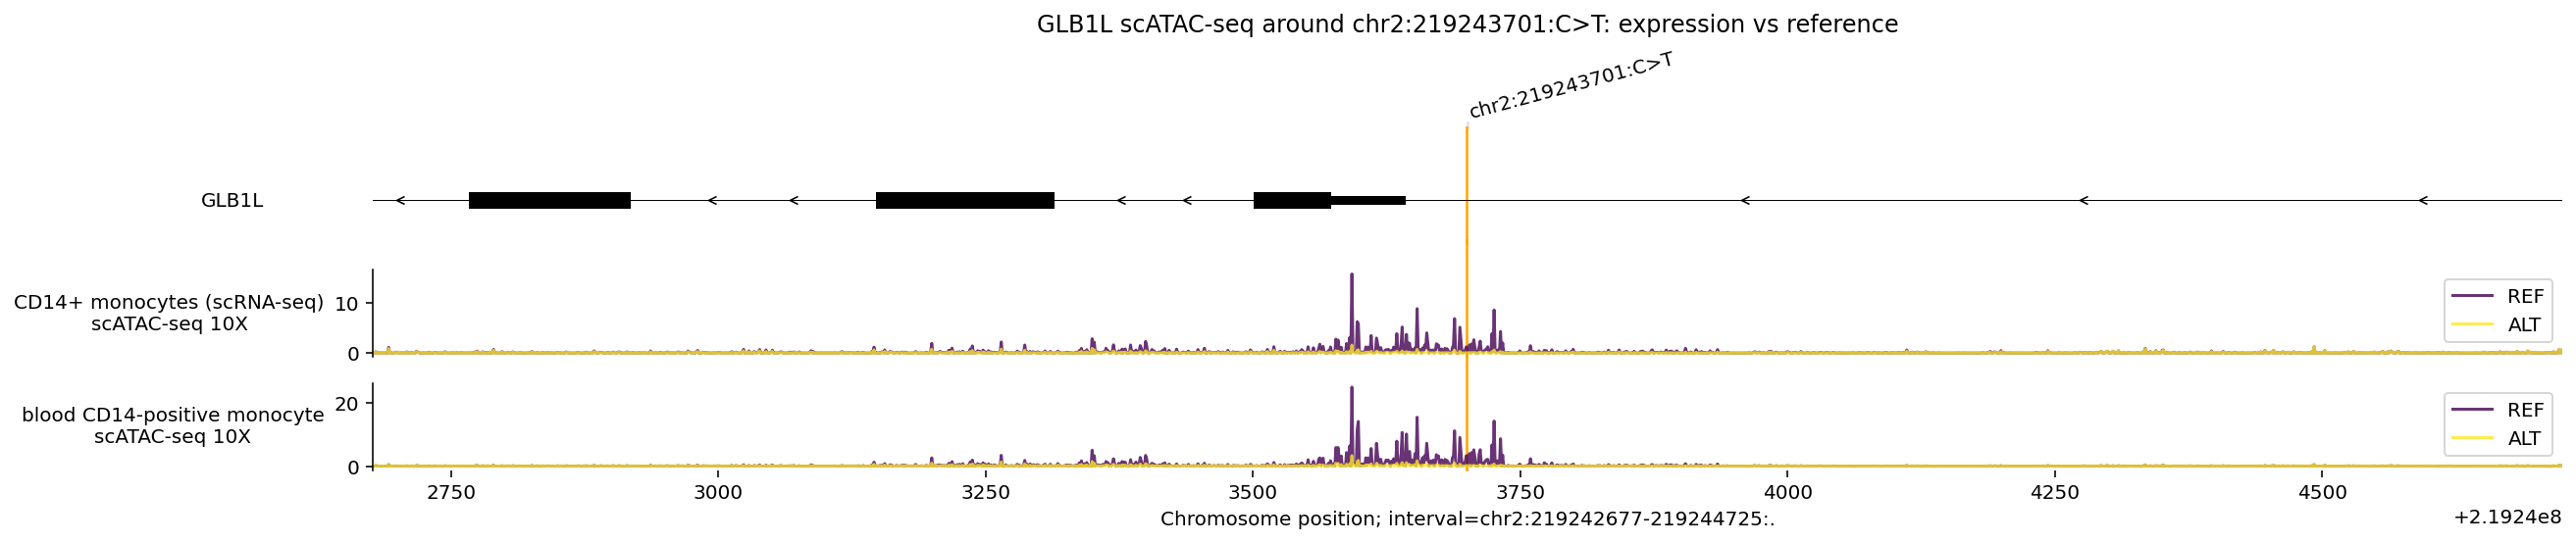

In [7]:
_ = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.OverlaidTracks(
            tdata=expr_sc_atac,
            ylabel_template='{biosample_name}\n{Assay title}',
        ),
        plot_components.OverlaidTracks(
            tdata=ref_cond_sc_atac,
            ylabel_template='{biosample_name}\n{Assay title}',
        ),
    ],
    interval=variant.reference_interval.resize(2048),
    annotations=[plot_components.VariantAnnotation([variant])],
    title='GLB1L scATAC-seq around chr2:219243701:C>T: expression vs reference',
)
plt.show()

Next, we compare gene-level single-cell expression of *GLB1L* on a log scale.
The denoised output requires only a strand filter; from the reference condition,
we select the matching 10x 5' protocol channel on the negative strand:

In [8]:
expr_ref = expr_output.reference.sc_gene_expression_denoised.filter_to_protein_coding()
expr_alt = expr_output.alternate.sc_gene_expression_denoised.filter_to_protein_coding()
expr_sc_gex = {
    'REF': expr_ref.filter_to_negative_strand(),
    'ALT': expr_alt.filter_to_negative_strand(),
}

ref_ref = ref_cond_output.reference.sc_gene_expression.filter_to_protein_coding()
ref_alt = ref_cond_output.alternate.sc_gene_expression.filter_to_protein_coding()
ref_mask = (
    ref_ref.track_metadata['name'].str.contains('scRNA-seq 10X 5-cellranger-cell')
    & (ref_ref.track_metadata['strand'] == '-')
).to_numpy()
ref_cond_sc_gex = {
    'REF': ref_ref.filter_tracks(ref_mask),
    'ALT': ref_alt.filter_tracks(ref_mask),
}

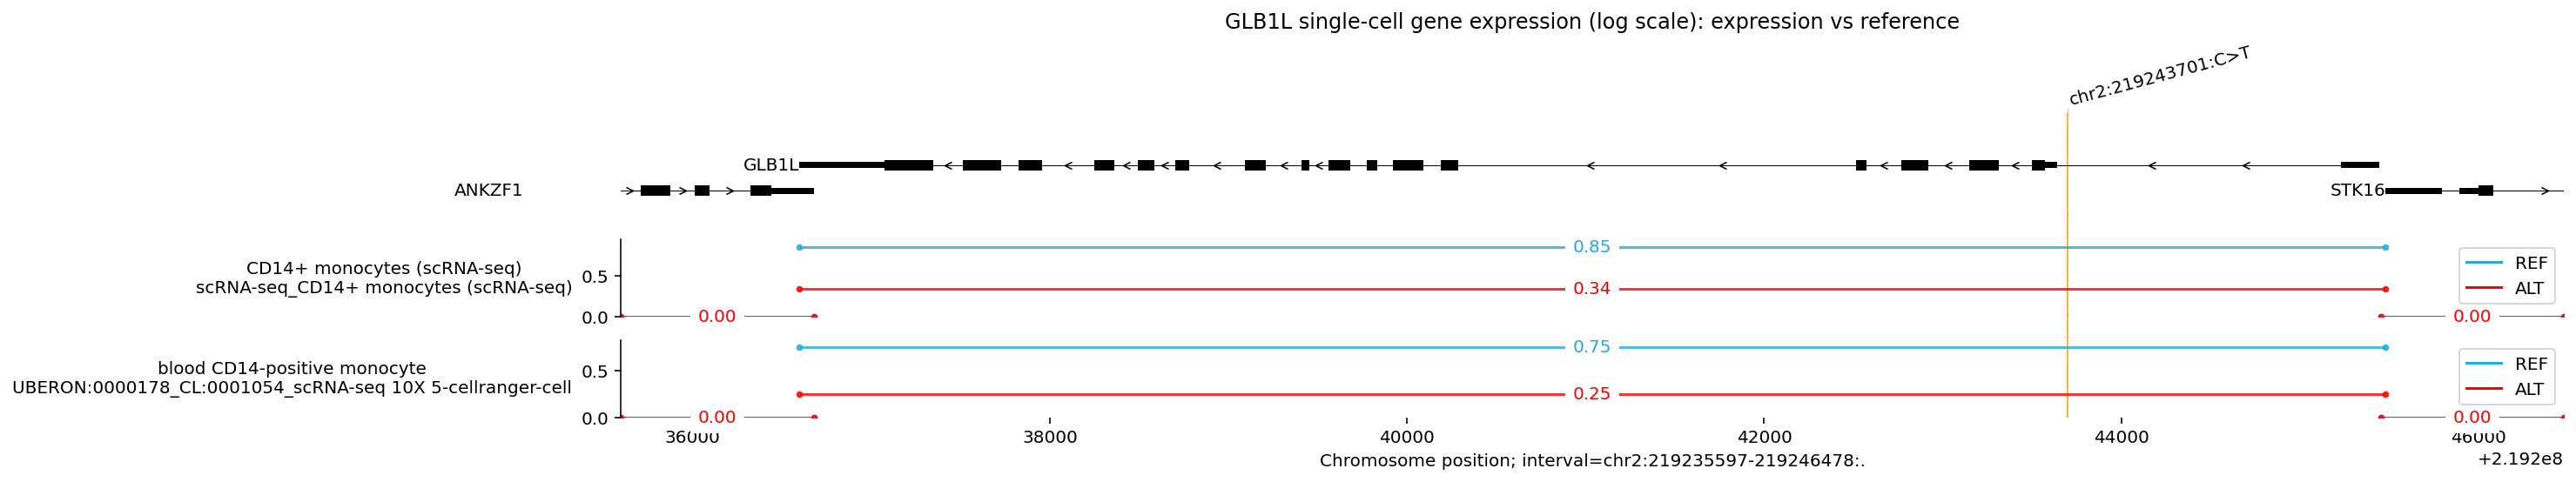

In [9]:
_ = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.OverlaidGeneExpression(
            gdata=expr_sc_gex,
            colors={'REF': '#22AAE1', 'ALT': 'red'},
            log_scale=True,
            ylabel_template='{biosample_name}\n{name}',
        ),
        plot_components.OverlaidGeneExpression(
            gdata=ref_cond_sc_gex,
            colors={'REF': '#22AAE1', 'ALT': 'red'},
            log_scale=True,
            ylabel_template='{biosample_name}\n{name}',
        ),
    ],
    interval=plot_interval,
    annotations=[plot_components.VariantAnnotation([variant])],
    title='GLB1L single-cell gene expression (log scale): expression vs reference',
)
plt.show()

Both condition modes predict local loss of single-cell accessibility at
chr2:219243701:C>T together with lower *GLB1L* expression on the T alternate
allele. Under expression conditioning, every output other than single-cell gene
expression (here `SC_ATAC`) is imputed from the cell embedding; see
[Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html).

## Score the variant with expression conditioning

`dna_model.score_variant` accepts the same `cell_conditioning` and
`cell_condition_name` arguments. Scoring `SC_ATAC` and `SC_GENE_EXPRESSION_DENOISED`
returns a single denoised expression score for *GLB1L* alongside chromatin
accessibility:

In [10]:
expr_scores = dna_model.score_variant(
    interval=interval,
    variant=variant,
    variant_scorers=[
        variant_scorers.RECOMMENDED_VARIANT_SCORERS['SC_ATAC'],
        variant_scorers.RECOMMENDED_VARIANT_SCORERS[
            'SC_GENE_EXPRESSION_DENOISED'
        ],
    ],
    cell_conditioning=monocyte_cells,
    cell_condition_name='CD14+ monocytes (scRNA-seq)',
)

tidy_expr_scores = variant_scorers.tidy_scores(expr_scores)
tidy_expr_scores[
    tidy_expr_scores['gene_name'].isna()
    | (tidy_expr_scores['gene_name'] == 'GLB1L')
][['variant_id', 'gene_name', 'output_type', 'track_name', 'raw_score']]

,variant_id,gene_name,output_type,track_name,raw_score
0,chr2:219243701:C>T,None,SC_ATAC,EasySci-ATAC-easy_sci-nuclear_CD14+ monocytes ...,-2.077359
1,chr2:219243701:C>T,None,SC_ATAC,SHARE-seq-cellranger-nuclear_CD14+ monocytes (...,-1.977591
2,chr2:219243701:C>T,None,SC_ATAC,scATAC-seq 10X-bowtie2-nuclear_CD14+ monocytes...,-2.375183
3,chr2:219243701:C>T,None,SC_ATAC,scATAC-seq 10X-cellranger-nuclear_CD14+ monocy...,-2.367137
4,chr2:219243701:C>T,None,SC_ATAC,sciATAC-seq-bowtie2-nuclear_CD14+ monocytes (s...,-2.406158
31,chr2:219243701:C>T,GLB1L,SC_GENE_EXPRESSION_DENOISED,scRNA-seq_CD14+ monocytes (scRNA-seq),-1.737557


## Inspect cell embeddings

`dna_model.encode_cells` runs AlphaGenome 2's single-cell autoencoder (trained on
CELLxGENE) without evaluating the DNA sequence model, returning the cell
embeddings that expression conditioning averages over. Use it to check how your
cells are represented before running predictions:

- **Cell states**: Different biological cell types and states should separate in
  embedding space.
- **Batch effects**: The encoder does not explicitly correct batch effects. For
  data with batch effects across donors or replicates, stratify the input to
  `cell_conditioning` to control for these effects.

Here we subsample cells from a single donor (BR2028) in the same Gong *et al.*
blood dataset across immune cell types, encode them with `dna_model.encode_cells`,
and inspect the resulting embedding space with Scanpy:

In [13]:
DONOR_FILTER = (
    f"dataset_id == '{GONG_DATASET_ID}' and donor_id == 'BR2028'"
)
N_DONOR_CELLS = 2000
MIN_CELLS_PER_TYPE = 20
def sample_cells_by_type(obs, n_cells, min_cells_per_type, rng):
  """Samples cells in proportion to cell type, as contiguous runs.
  Census stores each donor's cells grouped by cell type, so taking one
  contiguous run of IDs per cell type is much faster to download than a
  fully random sample with the same cell-type composition.
  """
  counts = obs['cell_type'].value_counts()
  expected = counts / counts.sum() * n_cells
  expected = expected[expected >= min_cells_per_type]
  expected = expected / expected.sum() * n_cells
  alloc = np.floor(expected).astype(int)
  remainder = (expected - alloc).sort_values(ascending=False)
  alloc[remainder.index[: n_cells - alloc.sum()]] += 1
  ids = []
  for cell_type, k in alloc.items():
    type_ids = np.sort(
        obs.loc[obs['cell_type'] == cell_type, 'soma_joinid'].to_numpy()
    )
    start = rng.integers(0, len(type_ids) - k + 1)
    ids.append(type_ids[start : start + k])
  return np.sort(np.concatenate(ids))
# Downloading the data from CELLxGENE Census takes ~30 seconds.
with cellxgene_census.open_soma(census_version='latest') as census:
  donor_obs = (
      census['census_data']['homo_sapiens']
      .obs.read(
          value_filter=DONOR_FILTER,
          column_names=['soma_joinid', 'cell_type'],
      )
      .concat()
      .to_pandas()
  )
  donor_obs['cell_type'] = donor_obs['cell_type'].astype(str)
  donor_cell_ids = sample_cells_by_type(
      donor_obs,
      n_cells=N_DONOR_CELLS,
      min_cells_per_type=MIN_CELLS_PER_TYPE,
      rng=np.random.default_rng(42),
  )
  adata_donor = cellxgene_census.get_anndata(
      census=census,
      organism='Homo sapiens',
      obs_coords=donor_cell_ids,
  )

if adata_donor.raw is not None:
  adata_donor = adata_donor.raw.to_adata()
if 'feature_id' in adata_donor.var:
  adata_donor.var_names = adata_donor.var['feature_id'].astype(str).values

cell_type_counts = adata_donor.obs['cell_type'].value_counts()
keep_cell_types = cell_type_counts[cell_type_counts >= 20].index
adata_donor = adata_donor[
    adata_donor.obs['cell_type'].isin(keep_cell_types)
].copy()
adata_donor.obs['cell_type'] = (
    adata_donor.obs['cell_type'].cat.remove_unused_categories()
)

adata_donor.obsm['X_alphagenome'] = dna_model.encode_cells(cells=adata_donor)
sc.pp.neighbors(
    adata_donor, use_rep='X_alphagenome', metric='cosine', random_state=42
)
sc.tl.umap(adata_donor, random_state=42)
print(
    f'Encoded {adata_donor.n_obs} cells from donor BR2028 across'
    f' {adata_donor.obs["cell_type"].nunique()} cell types into shape'
    f' {adata_donor.obsm["X_alphagenome"].shape}'
)

  0%|          | 0/2 [00:00<?, ?it/s]

Encoded 2000 cells from donor BR2028 across 15 cell types into shape (2000, 256)


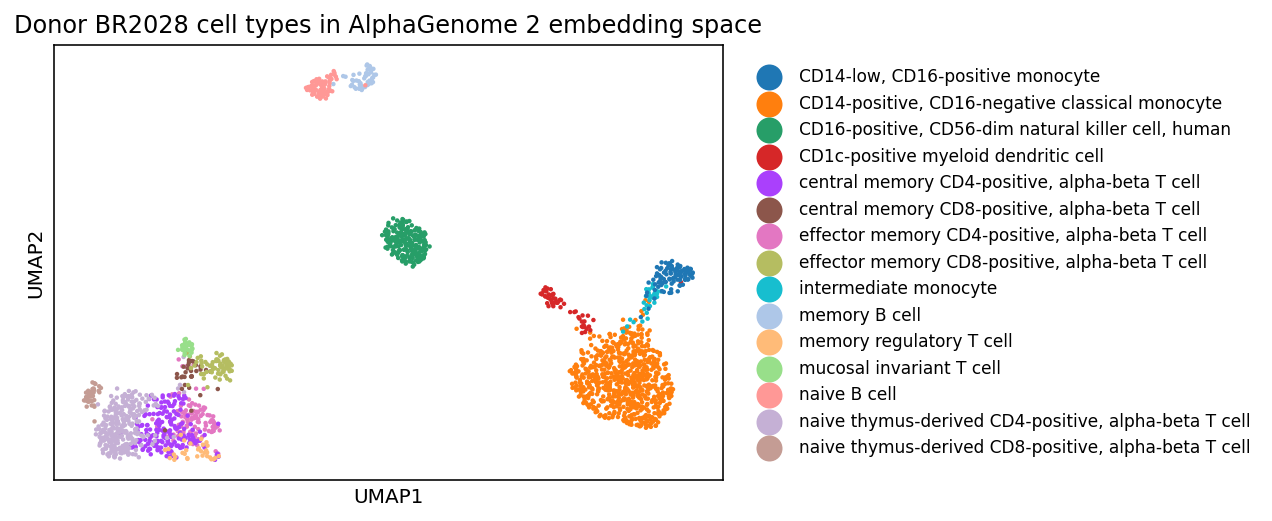

In [14]:
fig = sc.pl.umap(
    adata_donor,
    color='cell_type',
    size=20,
    title='Donor BR2028 cell types in AlphaGenome 2 embedding space',
    return_fig=True,
)
ax = fig.axes[0]
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    ncol=1,
    frameon=False,
    fontsize=8.5,
    markerscale=2.0,
)
fig.patch.set_facecolor('white')
plt.show()

## Next steps

- For fine-mapping a disease locus across primary immune populations in the ileum,
  see
  [Fine-mapping the *ETS2* locus](https://www.alphagenomedocs.com/colabs/v2/finemapping_ets2.html).
- For imputing unmeasured histone modification marks across reference conditions,
  see
  [Working with imputed tracks](https://www.alphagenomedocs.com/colabs/v2/imputing_unmeasured_tracks.html).